# Extra · the stochastic jet recipe

Not part of the pipeline. The benchmark jet of [`1_grb_model.ipynb`](../1_grb_model.ipynb) fixes every
input of the Nava (2020) / Abe et al. (2026) recipe at its population median. This notebook draws
**random events** from the same recipe instead, to see the population the benchmark stands for:

1. the input distributions ($E_{\gamma,\mathrm{iso}}$, $\theta_\mathrm{core}$, $\Gamma_\mathrm{core}$) whose medians define `BENCHMARK`;
2. the event-to-event scatter of the on-axis light curve;
3. the jet structure and why it is cut at $\theta_\mathrm{max}$;
4. why the simple *local* off-axis closure used here cannot describe far off-axis views, which is
   why the benchmark uses the element integral instead.

Code: `sample_events`, `grb_model_at_theta` in [`gwuls/grb_phenomenological.py`](../../gwuls/grb_phenomenological.py).
Physics: [`docs/emission_model.md`](../../docs/emission_model.md).

In [1]:
import sys
sys.path.insert(0, "../..")

import warnings
import numpy as np
import matplotlib.pyplot as plt

from gwuls import grb_phenomenological as ph
from gwuls import grb_model, paths

paths.ensure_dirs()
rng = np.random.default_rng(20260925)
plt.rcParams["figure.dpi"] = 100


/home/jjimenezq/anaconda3/envs/gw-gamma-global-uls/lib/python3.11/site-packages/igwn_ligolw/lsctables.py:57: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  import lal


## 1. Population draws

Two routes to $E_{\gamma,\mathrm{iso}}$ should agree: Abe et al. (2026) draw $E_\mathrm{peak}$ from a broken
power law and apply the Amati relation (`"via_epeak"`); Nava (2020) draws $E_{\gamma,\mathrm{iso}}$ directly
from the already-propagated broken power law (`"direct"`).

In [2]:
N_POP = 200_000

epeak_keV = ph.draw_epeak_keV(rng, N_POP)
egiso_via_epeak = ph.epeak_to_egiso_erg(epeak_keV)
egiso_direct = ph.draw_egiso_direct_erg(rng, N_POP)

q = [5, 50, 95]
print(f"E_peak [keV]                 5/50/95%: {np.percentile(epeak_keV, q)}")
print(f"E_gamma,iso via_epeak [erg]   5/50/95%: {np.percentile(egiso_via_epeak, q)}")
print(f"E_gamma,iso direct    [erg]   5/50/95%: {np.percentile(egiso_direct, q)}")
print(f"\nmedian ratio (direct / via_epeak): {np.median(egiso_direct) / np.median(egiso_via_epeak):.2f}")
print(f"E_iso,break quoted by Nava (2020) Eq. 1: {ph.EISO_BREAK_ERG:.2e} erg")


E_peak [keV]                 5/50/95%: [4.14977445e-01 1.45733423e+02 2.51849911e+03]
E_gamma,iso via_epeak [erg]   5/50/95%: [3.21473115e+47 2.02876993e+50 4.66201535e+51]
E_gamma,iso direct    [erg]   5/50/95%: [7.83288467e+47 3.85724261e+50 5.28406716e+51]

median ratio (direct / via_epeak): 1.90
E_iso,break quoted by Nava (2020) Eq. 1: 2.10e+51 erg


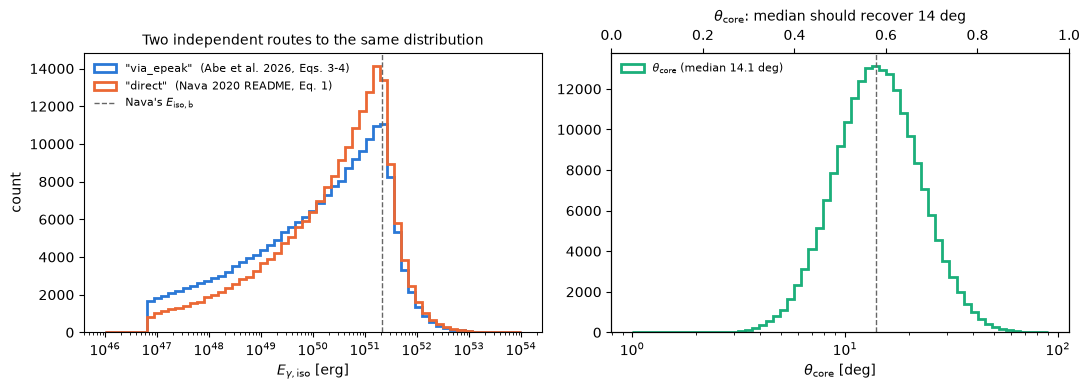

theta_core  median = 14.12 deg (expect 14 deg, Fong et al. 2015)
gamma_core  median = 199.6    (expect 200, Ghirlanda et al. 2019)


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bins_E = np.geomspace(1e46, 1e54, 60)
axes[0].hist(egiso_via_epeak, bins=bins_E, histtype="step", lw=2, color="#2a78d6",
             label='"via_epeak"  (Abe et al. 2026, Eqs. 3-4)')
axes[0].hist(egiso_direct, bins=bins_E, histtype="step", lw=2, color="#eb6834",
             label='"direct"  (Nava 2020 README, Eq. 1)')
axes[0].axvline(ph.EISO_BREAK_ERG, color="0.4", ls="--", lw=1, label=r"Nava's $E_{\rm iso,b}$")
axes[0].set_xscale("log"); axes[0].set_xlabel(r"$E_{\gamma,\rm iso}$ [erg]")
axes[0].set_ylabel("count"); axes[0].legend(fontsize=8, frameon=False)
axes[0].set_title("Two independent routes to the same distribution", fontsize=10)

theta_core = ph.draw_theta_core_deg(rng, N_POP)
gamma_core = ph.draw_gamma_core(rng, N_POP)
axes[1].hist(theta_core, bins=np.geomspace(1, 90, 60), histtype="step", lw=2, color="#1baf7a",
             label=r"$\theta_{\rm core}$ (median %.1f deg)" % np.median(theta_core))
ax2 = axes[1].twiny()
axes[1].set_xscale("log"); axes[1].set_xlabel(r"$\theta_{\rm core}$ [deg]")
axes[1].axvline(14, color="0.4", ls="--", lw=1)
axes[1].legend(fontsize=8, frameon=False, loc="upper left")
axes[1].set_title(r"$\theta_{\rm core}$: median should recover 14 deg", fontsize=10)
fig.tight_layout()
plt.show()

print(f"theta_core  median = {np.median(theta_core):.2f} deg (expect 14 deg, Fong et al. 2015)")
print(f"gamma_core  median = {np.median(gamma_core):.1f}    (expect 200, Ghirlanda et al. 2019)")


**Reading.** The two routes agree to within a factor of a few but not exactly ("direct" runs higher),
partly because no Amati scatter is applied. The benchmark uses `"via_epeak"`, the published route.

## 2. On-axis light curves

One broken power law in time per event: rise $\beta_1$ up to the deceleration time, decay $\beta_2$
after it, normalised through the 11 h anchor $E_{\gamma,\mathrm{iso}}\to L_{X,11h}\to L_\mathrm{TeV,11h}$.
No microphysics enters. Six random events:

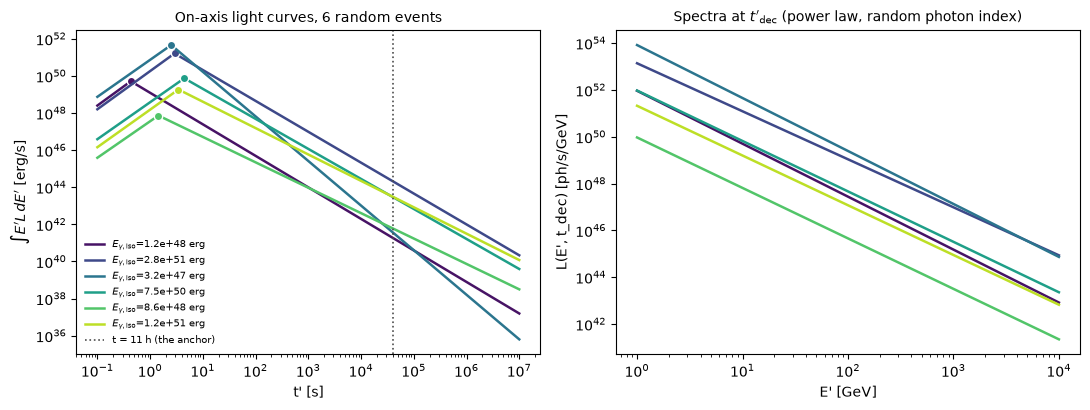

In [4]:
events = ph.sample_events(rng, 6, eiso_method="via_epeak")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
colors = plt.cm.viridis(np.linspace(0.05, 0.9, 6))
for i in range(6):
    m = ph.grb_model_at_theta(events, i, 0.0)
    t = m.time
    axes[0].loglog(t, m.light_curve(), color=colors[i], lw=1.8,
                    label=fr"$E_{{\gamma,\rm iso}}$={events['e_gamma_iso_erg'][i]:.1e} erg")
    axes[0].plot(*m.peak(), "o", ms=6, color=colors[i], mec="white", mew=1)
    axes[1].loglog(m.energy, m.at(m.energy, np.array([events["t_dec_core_s"][i]]))[:, 0],
                    color=colors[i], lw=1.8)

axes[0].axvline(ph.T_ANCHOR_S, color="0.3", ls=":", lw=1.2, label="t = 11 h (the anchor)")
axes[0].set_xlabel("t' [s]"); axes[0].set_ylabel(r"$\int E' L\,dE'$ [erg/s]")
axes[0].legend(fontsize=7, frameon=False, loc="lower left")
axes[0].set_title("On-axis light curves, 6 random events", fontsize=10)
axes[1].set_xlabel("E' [GeV]"); axes[1].set_ylabel("L(E', t_dec) [ph/s/GeV]")
axes[1].set_title(r"Spectra at $t'_{\rm dec}$ (power law, random photon index)", fontsize=10)
fig.tight_layout()
plt.show()


## 3. Jet structure and $\theta_\mathrm{max}$

Gaussian in energy and Lorentz factor (Abe et al. Eqs. 1–2). The jet is cut where $\Gamma_0 = 5$
(dotted lines).

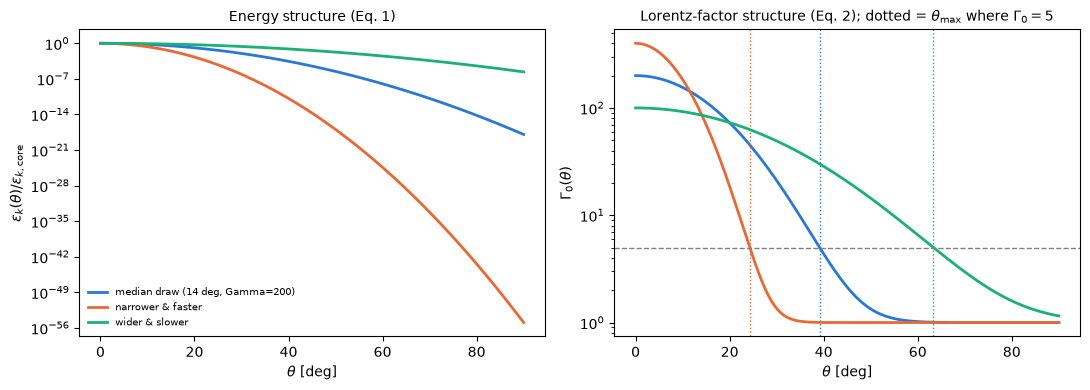

In [5]:
theta_grid = np.linspace(0, 90, 400)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for theta_core_i, gamma_core_i, label, color in [
    (14.0, 200.0, "median draw (14 deg, Gamma=200)", "#2a78d6"),
    (8.0, 400.0, "narrower & faster", "#eb6834"),
    (25.0, 100.0, "wider & slower", "#1baf7a"),
]:
    eps_frac, gamma0 = ph.jet_structure(theta_grid, theta_core_i, gamma_core_i)
    axes[0].semilogy(theta_grid, eps_frac, color=color, lw=2, label=label)
    axes[1].semilogy(theta_grid, gamma0, color=color, lw=2, label=label)
    tmax = ph.theta_max_deg(theta_core_i, gamma_core_i)
    axes[1].axvline(tmax, color=color, ls=":", lw=1)

axes[0].set_xlabel(r"$\theta$ [deg]"); axes[0].set_ylabel(r"$\varepsilon_k(\theta)/\varepsilon_{k,\rm core}$")
axes[0].set_title("Energy structure (Eq. 1)", fontsize=10); axes[0].legend(fontsize=7, frameon=False)
axes[1].axhline(ph.THETA_MAX_GAMMA0_FLOOR, color="0.5", ls="--", lw=1)
axes[1].set_xlabel(r"$\theta$ [deg]"); axes[1].set_ylabel(r"$\Gamma_0(\theta)$")
axes[1].set_title(r"Lorentz-factor structure (Eq. 2); dotted = $\theta_{\rm max}$ where $\Gamma_0=5$", fontsize=10)
fig.tight_layout()
plt.show()


Past that angle $t_\mathrm{dec}\propto E^{1/3}\Gamma_0^{-8/3}$ would *decrease* with angle, because
$\Gamma_0$ is floored at 1: the cut is a physical validity limit as well as a computational one.

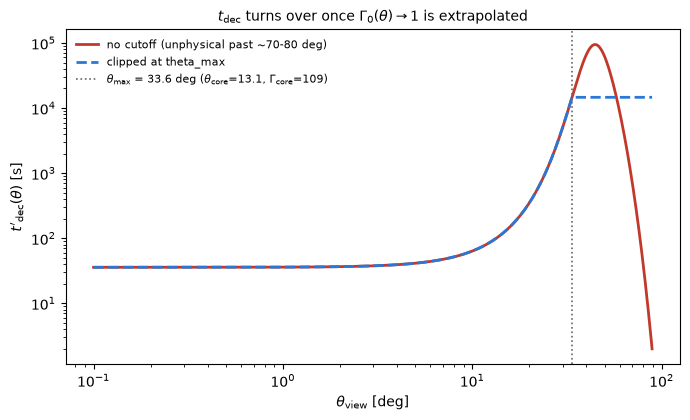

In [6]:
event = ph.sample_events(rng, 1, eiso_method="via_epeak")
theta_core_1, gamma_core_1 = event["theta_core_deg"][0], event["gamma_core"][0]
ek_core_1, l_peak_core_1 = event["ek_core_erg"][0], event["l_peak_core_erg_s"][0]
theta_max_1 = ph.theta_max_deg(theta_core_1, gamma_core_1)

theta_sweep = np.linspace(0.1, 89, 200)
eps_frac, gamma0 = ph.jet_structure(theta_sweep, theta_core_1, gamma_core_1)
t_dec_raw = ph.deceleration_time_s(ek_core_1 * eps_frac, gamma0)      # no cutoff -- shows the bug
t_dec_clipped = ph.deceleration_time_s(
    ek_core_1 * ph.jet_structure(np.minimum(theta_sweep, theta_max_1), theta_core_1, gamma_core_1)[0],
    ph.jet_structure(np.minimum(theta_sweep, theta_max_1), theta_core_1, gamma_core_1)[1],
)

fig, ax = plt.subplots(figsize=(7, 4.3))
ax.loglog(theta_sweep, t_dec_raw, color="#c0392b", lw=2, label="no cutoff (unphysical past ~70-80 deg)")
ax.loglog(theta_sweep, t_dec_clipped, color="#2a78d6", lw=2, ls="--", label="clipped at theta_max")
ax.axvline(theta_max_1, color="0.4", ls=":", lw=1.2,
           label=fr"$\theta_{{\rm max}}$ = {theta_max_1:.1f} deg ($\theta_{{\rm core}}$={theta_core_1:.1f}, $\Gamma_{{\rm core}}$={gamma_core_1:.0f})")
ax.set_xlabel(r"$\theta_{\rm view}$ [deg]"); ax.set_ylabel(r"$t'_{\rm dec}(\theta)$ [s]")
ax.set_title(r"$t_{\rm dec}$ turns over once $\Gamma_0(\theta) \to 1$ is extrapolated", fontsize=10)
ax.legend(fontsize=8, frameon=False)
fig.tight_layout()
plt.show()


## 4. The local closure against the catO5 files

Here an off-axis observer is given the light curve of the jet element on the line of sight, as its
own on-axis event (Nava 2020 Sec. 5). Below: peak time and peak luminosity against angle for 400
random events, with the five catO5 files on top. The catO5 files are five different events, so this
compares populations, not points.

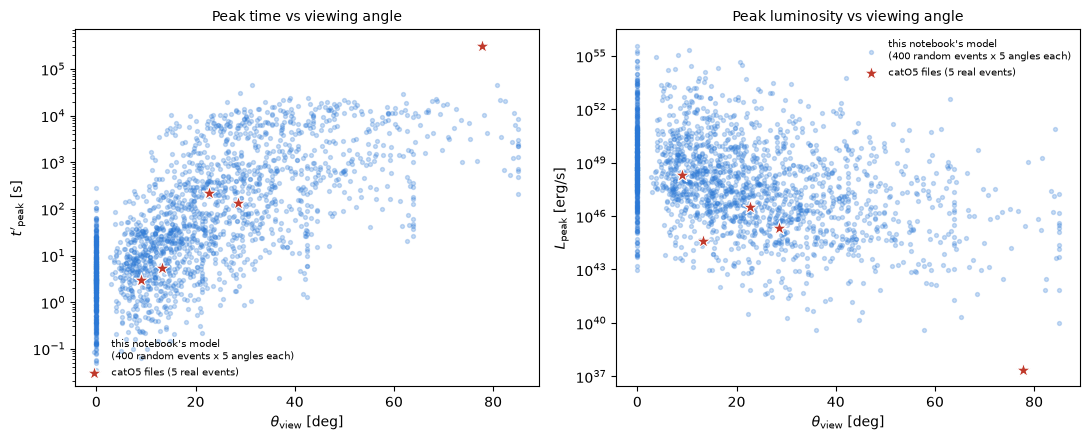

this notebook's t_peak span (5-95%): [5.11024038e-01 9.44640904e+03] s, over theta in [0, 85] deg (bounded by theta_max per event)
catO5 t_peak span:                   [9.1, 77.8] deg -> [3.03e+00, 3.19e+05] s


In [7]:
real = grb_model.GRBModelSet.from_inaf_dir(paths.GRB_MODEL_RAW_DIR)

N_CLOUD = 400
cloud_events = ph.sample_events(rng, N_CLOUD, eiso_method="via_epeak")
cloud_theta, cloud_tpk, cloud_lpk = [], [], []
with warnings.catch_warnings():
    warnings.simplefilter("ignore")   # theta_max clipping warnings -- expected and handled
    for i in range(N_CLOUD):
        tmax_i = ph.theta_max_deg(cloud_events["theta_core_deg"][i], cloud_events["gamma_core"][i])
        for frac in [0.0, 0.25, 0.5, 0.75, 1.0]:
            theta_i = frac * min(tmax_i, 85.0)
            m = ph.grb_model_at_theta(cloud_events, i, theta_i)
            t_pk, l_pk = m.peak()
            cloud_theta.append(theta_i); cloud_tpk.append(t_pk); cloud_lpk.append(l_pk)
cloud_theta, cloud_tpk, cloud_lpk = map(np.array, (cloud_theta, cloud_tpk, cloud_lpk))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, y, ylabel in [(axes[0], cloud_tpk, r"$t'_{\rm peak}$ [s]"),
                       (axes[1], cloud_lpk, r"$L_{\rm peak}$ [erg/s]")]:
    ax.scatter(cloud_theta, y, s=8, alpha=0.25, color="#2a78d6",
               label=f"this notebook's model\n({N_CLOUD} random events x 5 angles each)")
    real_t, real_y = real.angles_deg, [real.models[th].peak()[0 if ylabel.startswith("$t") else 1]
                                        for th in real.angles_deg]
    ax.scatter(real_t, real_y, s=120, marker="*", color="#c0392b", zorder=5,
               label="catO5 files (5 real events)", edgecolor="white", linewidth=0.8)
    ax.set_yscale("log"); ax.set_xlabel(r"$\theta_{\rm view}$ [deg]"); ax.set_ylabel(ylabel)
    ax.legend(fontsize=7, frameon=False, loc="lower left" if ylabel.startswith("$t") else "upper right")
axes[0].set_title("Peak time vs viewing angle", fontsize=10)
axes[1].set_title("Peak luminosity vs viewing angle", fontsize=10)
fig.tight_layout()
plt.show()

print(f"this notebook's t_peak span (5-95%): {np.percentile(cloud_tpk, [5, 95])} s, over "
      f"theta in [0, {cloud_theta.max():.0f}] deg (bounded by theta_max per event)")
print(f"catO5 t_peak span:                   [{real.angles_deg.min():.1f}, {real.angles_deg.max():.1f}] deg "
      f"-> [{min(real.models[th].peak()[0] for th in real.angles_deg):.2e}, "
      f"{max(real.models[th].peak()[0] for th in real.angles_deg):.2e}] s")


**Reading.** Both get later and fainter with angle, but the local closure cannot go past
$\theta_\mathrm{max}$ (typically tens of degrees), so it never reaches the late peak of the 77.8° file.
Far off-axis, the flux comes from the core decelerating until its beaming cone reaches the line of
sight, which only the full element integral captures. That is why
[`1_grb_model.ipynb`](../1_grb_model.ipynb) uses it, and it matches all five files there.

Other simplifications of this module: $t_\mathrm{dec}$ from the collimated (not isotropic) energy, about
5× earlier; the light curve normalised over 1 GeV–10 TeV rather than 0.3–1 TeV; density fixed at
0.1 cm⁻³; no Amati scatter.